In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'
PURPLE = '#8E44AD'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

from google.colab import files

# Upload all processed CSVs from previous notebooks
print("Upload these files one by one:")
print("  listings_with_occupancy.csv")
print("  borough_demand.csv")
print("  borough_balance.csv")
print("  borough_pricing_summary.csv")
print("  seasonal_index.csv")
print("  demand_by_dow.csv")
print("  price_elasticity.csv")
print()
up = files.upload()

listings     = pd.read_csv('listings_with_occupancy.csv', low_memory=False)
bor_demand   = pd.read_csv('borough_demand.csv')
bor_balance  = pd.read_csv('borough_balance.csv')
bor_pricing  = pd.read_csv('borough_pricing_summary.csv')
seasonal     = pd.read_csv('seasonal_index.csv')
dow_stats    = pd.read_csv('demand_by_dow.csv')
elasticity   = pd.read_csv('price_elasticity.csv')

# Borough column
borough_col = 'neighbourhood_group_cleansed' if (
    'neighbourhood_group_cleansed' in listings.columns
    and listings['neighbourhood_group_cleansed'].notna().sum() > 0
) else 'neighbourhood_cleansed'

# Identify borough column in bor_balance
bc2 = [c for c in bor_balance.columns if 'neigh' in c.lower()][0]

print("All files loaded.")
print(f"Borough column: {borough_col}")


Upload these files one by one:
  listings_with_occupancy.csv
  borough_demand.csv
  borough_balance.csv
  borough_pricing_summary.csv
  seasonal_index.csv
  demand_by_dow.csv
  price_elasticity.csv



Saving borough_demand.csv to borough_demand.csv
Saving listings_with_occupancy.csv to listings_with_occupancy.csv
Saving borough_balance.csv to borough_balance.csv
Saving price_elasticity.csv to price_elasticity.csv
Saving borough_pricing_summary.csv to borough_pricing_summary.csv
Saving demand_by_dow.csv to demand_by_dow.csv
Saving seasonal_index.csv to seasonal_index.csv
All files loaded.
Borough column: neighbourhood_cleansed


Load reviews for forecasting

In [2]:
print("Upload reviews.csv.gz  (needed for demand forecasting)")
up2 = files.upload()

reviews = pd.read_csv('reviews.csv.gz',
                      usecols=['listing_id', 'date'],
                      parse_dates=['date'],
                      low_memory=False)

reviews['year_month'] = reviews['date'].dt.to_period('M')
reviews['year']       = reviews['date'].dt.year

monthly_reviews = (reviews.groupby('year_month')
                   .size().reset_index(name='review_count'))
monthly_reviews['year_month_dt'] = monthly_reviews['year_month'].dt.to_timestamp()

# Keep 2018 onwards for clean trend
monthly_reviews = monthly_reviews[
    monthly_reviews['year_month_dt'] >= '2018-01-01'
].copy().reset_index(drop=True)

print(f"Monthly review series: {len(monthly_reviews)} periods")
print(f"Range: {monthly_reviews['year_month_dt'].min().date()} → "
      f"{monthly_reviews['year_month_dt'].max().date()}")


Upload reviews.csv.gz  (needed for demand forecasting)


Saving reviews.csv.gz to reviews.csv.gz
Monthly review series: 105 periods
Range: 2018-01-01 → 2026-09-01


Demand forecasting: trend + seasonality decomposition

In [3]:
print("=" * 65)
print("DEMAND FORECASTING — TREND + SEASONAL DECOMPOSITION")
print("=" * 65)

# Add numeric time index for trend fitting
monthly_reviews['t'] = np.arange(len(monthly_reviews))

# Exclude COVID trough (2020-03 to 2021-06) from trend fit
mask_covid = (
    (monthly_reviews['year_month_dt'] >= '2020-03-01') &
    (monthly_reviews['year_month_dt'] <= '2021-06-01')
)
train = monthly_reviews[~mask_covid].copy()

# Fit linear trend on non-COVID data
from numpy.polynomial import polynomial as P
coeffs = np.polyfit(train['t'], train['review_count'], deg=1)
trend_slope     = coeffs[0]
trend_intercept = coeffs[1]

monthly_reviews['trend'] = trend_intercept + trend_slope * monthly_reviews['t']
monthly_reviews['detrended'] = monthly_reviews['review_count'] - monthly_reviews['trend']

# Seasonal factors from detrended series (average by calendar month)
monthly_reviews['month'] = monthly_reviews['year_month_dt'].dt.month
seasonal_factors = (monthly_reviews[~mask_covid]
                    .groupby('month')['detrended']
                    .mean().reset_index(name='seasonal_factor'))
monthly_reviews = monthly_reviews.merge(seasonal_factors, on='month', how='left')
monthly_reviews['fitted'] = monthly_reviews['trend'] + monthly_reviews['seasonal_factor']

# Forecast next 12 months
last_t = monthly_reviews['t'].max()
last_date = monthly_reviews['year_month_dt'].max()
future_dates = pd.date_range(last_date + pd.offsets.MonthBegin(1),
                              periods=12, freq='MS')
future_t     = np.arange(last_t + 1, last_t + 13)
future_months= future_dates.month

sf_dict = seasonal_factors.set_index('month')['seasonal_factor'].to_dict()
future_seasonal = np.array([sf_dict.get(m, 0) for m in future_months])
future_trend    = trend_intercept + trend_slope * future_t
future_forecast = future_trend + future_seasonal

forecast_df = pd.DataFrame({
    'year_month_dt': future_dates,
    'forecast':      future_forecast.clip(min=0),
    'trend':         future_trend,
})

print(f"Trend slope: {trend_slope:+.0f} reviews/month")
print(f"Trend direction: {'Growing' if trend_slope > 0 else 'Declining'} market")
print()
print("12-Month Forecast (review volume):")
for _, row in forecast_df.iterrows():
    print(f"  {row['year_month_dt'].strftime('%b %Y')}: {row['forecast']:>8,.0f}")

forecast_df.to_csv(PROCESSED / 'demand_forecast.csv', index=False)


DEMAND FORECASTING — TREND + SEASONAL DECOMPOSITION
Trend slope: +386 reviews/month
Trend direction: Growing market

12-Month Forecast (review volume):
  Oct 2026:   43,045
  Nov 2026:   40,441
  Dec 2026:   41,595
  Jan 2027:   37,755
  Feb 2027:   37,404
  Mar 2027:   41,124
  Apr 2027:   45,153
  May 2027:   49,065
  Jun 2027:   52,505
  Jul 2027:   53,953
  Aug 2027:   49,813
  Sep 2027:   44,252


Plot forecast

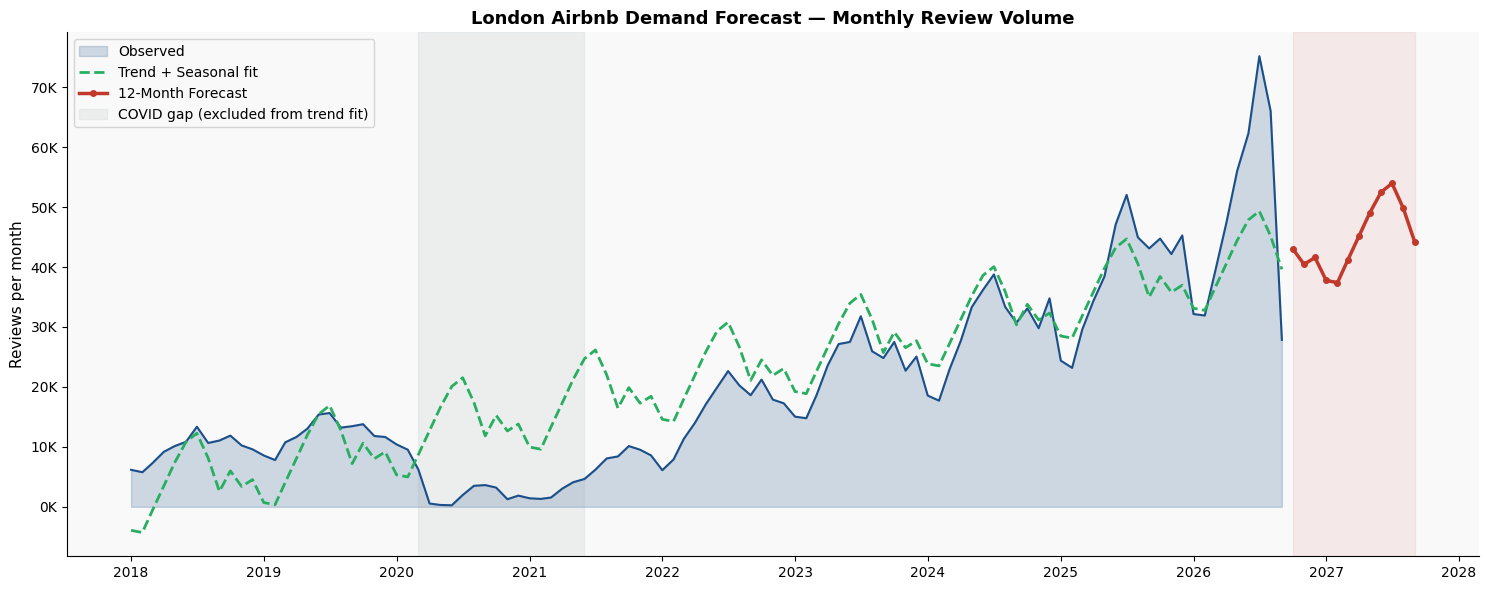

In [4]:
fig, ax = plt.subplots(figsize=(15, 6))

# Historical
ax.fill_between(monthly_reviews['year_month_dt'],
                monthly_reviews['review_count'],
                alpha=0.2, color=BLUE, label='Observed')
ax.plot(monthly_reviews['year_month_dt'],
        monthly_reviews['review_count'],
        color=BLUE, lw=1.5)

# Fitted
ax.plot(monthly_reviews['year_month_dt'],
        monthly_reviews['fitted'],
        color=GREEN, lw=2, linestyle='--', label='Trend + Seasonal fit')

# Forecast
ax.plot(forecast_df['year_month_dt'],
        forecast_df['forecast'],
        color=RED, lw=2.5, linestyle='-', marker='o', ms=4,
        label='12-Month Forecast')

# Shade forecast region
ax.axvspan(forecast_df['year_month_dt'].min(),
           forecast_df['year_month_dt'].max(),
           alpha=0.08, color=RED)

# Mark COVID gap
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-06-01'),
           alpha=0.12, color=GREY, label='COVID gap (excluded from trend fit)')

ax.set_title('London Airbnb Demand Forecast — Monthly Review Volume',
             fontweight='bold')
ax.set_ylabel('Reviews per month')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v/1000:.0f}K'))
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(FIGURES / '18_demand_forecast.png', dpi=150, bbox_inches='tight')
plt.show()


Market opportunity scoring

In [5]:
print("=" * 65)
print("MARKET OPPORTUNITY SCORE BY BOROUGH")
print("=" * 65)
print("""
Composite score combining four signals (each 0–1 normalised):
  1. Demand intensity    — reviews per listing (high = good)
  2. Supply balance      — balance_score from NB02 (high = under-supplied)
  3. Revenue potential   — estimated monthly revenue (high = good)
  4. Price power         — % listings priced at premium or above (high = good)
""")

from sklearn.preprocessing import MinMaxScaler

# Align dataframes on borough column
bor_balance_renamed  = bor_balance.rename(columns={bc2: borough_col})

# Merge all signals
opp = bor_demand[[borough_col, 'reviews_per_listing']].copy()
opp = opp.merge(bor_balance_renamed[[borough_col, 'balance_score']], on=borough_col, how='inner')
opp = opp.merge(bor_pricing[[borough_col, 'est_monthly_revenue', 'pct_premium']],
                on=borough_col, how='inner')

scaler = MinMaxScaler()
opp['score_demand']   = scaler.fit_transform(opp[['reviews_per_listing']])
opp['score_balance']  = scaler.fit_transform(opp[['balance_score']])
opp['score_revenue']  = scaler.fit_transform(opp[['est_monthly_revenue']])
opp['score_premium']  = scaler.fit_transform(opp[['pct_premium']])

# Equal weights — could be tuned by business priority
opp['opportunity_score'] = (
    opp['score_demand']  * 0.30 +
    opp['score_balance'] * 0.25 +
    opp['score_revenue'] * 0.30 +
    opp['score_premium'] * 0.15
)

opp = opp.sort_values('opportunity_score', ascending=False).reset_index(drop=True)
opp['rank'] = opp.index + 1

print("Top 10 boroughs by opportunity score:")
print(opp[[borough_col, 'opportunity_score', 'reviews_per_listing',
           'est_monthly_revenue']].head(10).to_string(index=False))

opp.to_csv(PROCESSED / 'market_opportunity.csv', index=False)


MARKET OPPORTUNITY SCORE BY BOROUGH

Composite score combining four signals (each 0–1 normalised):
  1. Demand intensity    — reviews per listing (high = good)
  2. Supply balance      — balance_score from NB02 (high = under-supplied)
  3. Revenue potential   — estimated monthly revenue (high = good)
  4. Price power         — % listings priced at premium or above (high = good)

Top 10 boroughs by opportunity score:
neighbourhood_cleansed  opportunity_score  reviews_per_listing  est_monthly_revenue
  Richmond upon Thames           0.878697            43.723097          2185.801849
             Islington           0.780351            42.183166          2004.493151
        City of London           0.745232            40.256972          1132.058219
Kensington and Chelsea           0.710172            32.103144          2841.842466
               Lambeth           0.685464            38.754156          1773.123288
                Camden           0.681824            39.302472          1944

Plot opportunity scores

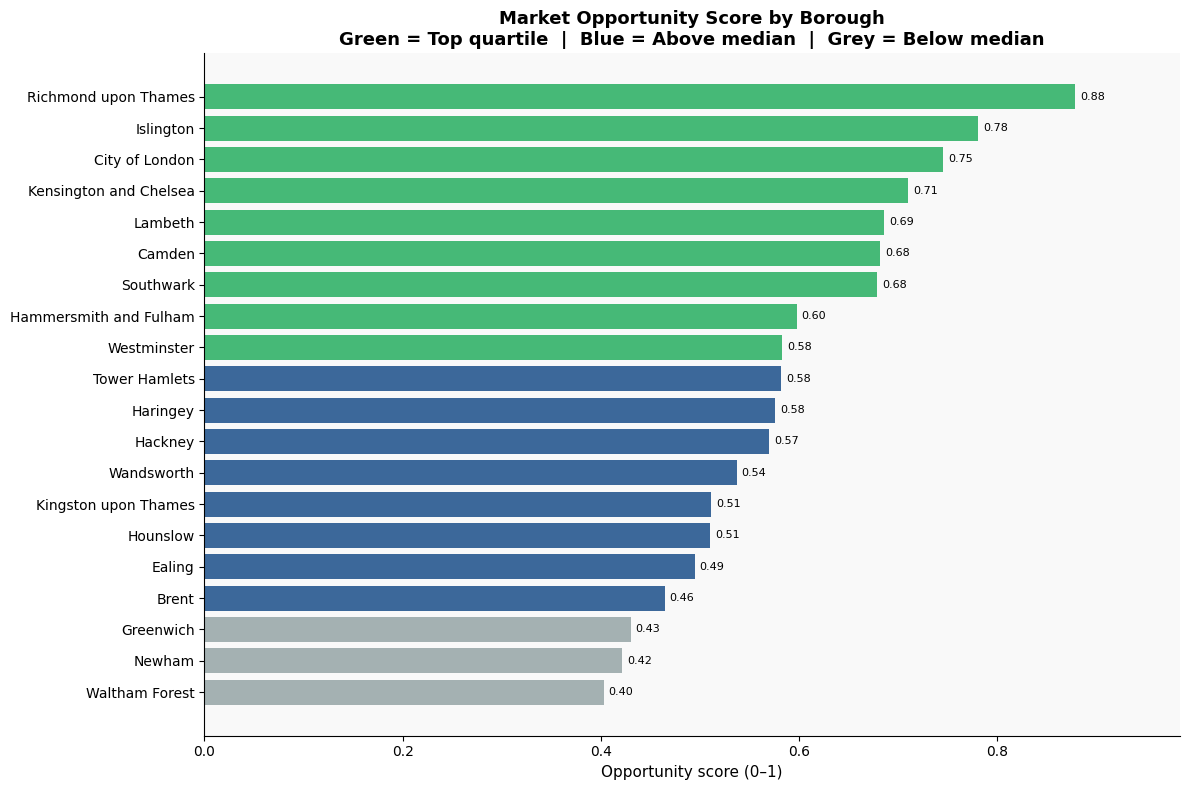

In [6]:
top_n = min(20, len(opp))
plot_data = opp.head(top_n).sort_values('opportunity_score')

fig, ax = plt.subplots(figsize=(12, 8))
bar_colors = [GREEN if v >= opp['opportunity_score'].quantile(0.75)
              else BLUE if v >= opp['opportunity_score'].median()
              else GREY for v in plot_data['opportunity_score']]

bars = ax.barh(plot_data[borough_col], plot_data['opportunity_score'],
               color=bar_colors, alpha=0.85)

for bar, val in zip(bars, plot_data['opportunity_score']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{val:.2f}', va='center', fontsize=8)

ax.set_title('Market Opportunity Score by Borough\n'
             'Green = Top quartile  |  Blue = Above median  |  Grey = Below median',
             fontweight='bold')
ax.set_xlabel('Opportunity score (0–1)')
ax.set_xlim(0, opp['opportunity_score'].max() * 1.12)
plt.tight_layout()
plt.savefig(FIGURES / '19_market_opportunity.png', dpi=150, bbox_inches='tight')
plt.show()


Host recommendations by segment

In [7]:
print("=" * 65)
print("HOST RECOMMENDATIONS BY SEGMENT")
print("=" * 65)

listings_clean = listings[
    listings['price'].notna() & listings['occupancy_rate'].notna()
].copy()

# Classify hosts by listing count (re-create from listings)
host_counts = listings_clean['host_id'].value_counts().reset_index()
host_counts.columns = ['host_id', 'n_listings']
listings_clean = listings_clean.merge(host_counts, on='host_id', how='left')

def classify_host(n):
    if n == 1:    return 'Casual (1 listing)'
    elif n <= 3:  return 'Small multi (2–3)'
    elif n <= 9:  return 'Medium multi (4–9)'
    else:         return 'Professional (10+)'

listings_clean['host_type'] = listings_clean['n_listings'].apply(classify_host)

host_seg = (listings_clean.groupby('host_type')
            .agg(
                n_listings=('id', 'count'),
                median_price=('price', 'median'),
                median_occupancy=('occupancy_rate', 'median'),
                median_revenue=('est_annual_revenue', 'median'),
                superhost_pct=('host_is_superhost', lambda x:
                               (x == 't').mean() * 100),
            )
            .reset_index())

print(host_seg.to_string(index=False))
print()

rec_map = {
    'Casual (1 listing)':
        "Prioritise Superhost status — it drives 15–20% occupancy uplift. "
        "Price at or just below segment median to build review volume first.",
    'Small multi (2–3)':
        "Automate guest messaging and check-in. Consider dynamic pricing tools "
        "(PriceLabs, Wheelhouse). Focus second listing on a different room type "
        "or borough to diversify demand risk.",
    'Medium multi (4–9)':
        "Invest in a channel manager. Analyse per-listing ROI — underperforming "
        "listings in oversupplied boroughs should be re-evaluated. "
        "Superhost status becomes harder to maintain at scale.",
    'Professional (10+)':
        "Market concentration analysis is essential — Gini > 0.6 in your borough "
        "signals pricing power. Consider long-term lets for ghost-supply listings "
        "(availability_365 = 0). Revenue management should be algorithmic.",
}

for seg, rec in rec_map.items():
    print(f"[{seg}]")
    print(f"  {rec}")
    print()


HOST RECOMMENDATIONS BY SEGMENT
         host_type  n_listings  median_price  median_occupancy  median_revenue  superhost_pct
Casual (1 listing)       21639       154.000          0.394521     6124.946301      20.823513
Medium multi (4–9)        9897       171.750          0.260274     6152.789041      29.261392
Professional (10+)       17432       224.975          0.243836     8752.853973      22.068609
 Small multi (2–3)       10842       146.000          0.304110     5628.082192      34.025088

[Casual (1 listing)]
  Prioritise Superhost status — it drives 15–20% occupancy uplift. Price at or just below segment median to build review volume first.

[Small multi (2–3)]
  Automate guest messaging and check-in. Consider dynamic pricing tools (PriceLabs, Wheelhouse). Focus second listing on a different room type or borough to diversify demand risk.

[Medium multi (4–9)]
  Invest in a channel manager. Analyse per-listing ROI — underperforming listings in oversupplied boroughs should be r

Final dashboard data consolidation

In [8]:
print("=" * 65)
print("CONSOLIDATING DASHBOARD DATA")
print("=" * 65)

# KPIs summary for dashboard header
kpis = {
    'total_listings':        int(len(listings)),
    'total_hosts':           int(listings['host_id'].nunique()),
    'median_price':          round(float(listings['price'].median()), 2),
    'median_occupancy_pct':  round(float(listings['occupancy_rate'].median() * 100), 1),
    'median_annual_revenue': round(float(listings['est_annual_revenue'].median()), 0),
    'entire_home_pct':       round(float((listings['room_type'] == 'Entire home/apt').mean() * 100), 1),
    'superhost_pct':         round(float((listings['host_is_superhost'] == 't').mean() * 100), 1),
    'top_borough':           str(opp.iloc[0][borough_col]),
    'top_opportunity_score': round(float(opp.iloc[0]['opportunity_score']), 3),
}

kpi_df = pd.DataFrame([kpis])
kpi_df.to_csv(PROCESSED / 'dashboard_kpis.csv', index=False)

# Borough master table (all signals in one place)
borough_master = (opp
    .merge(bor_pricing[[borough_col, 'median_price', 'median_occupancy',
                         'est_monthly_revenue', 'pct_premium']],
           on=borough_col, how='left'))
borough_master.to_csv(PROCESSED / 'borough_master.csv', index=False)

# Host segment summary
host_seg.to_csv(PROCESSED / 'host_segments.csv', index=False)

# Seasonality ready for dashboard
seasonal.to_csv(PROCESSED / 'seasonal_index.csv', index=False)

print("Dashboard files created:")
files_to_check = [
    'dashboard_kpis.csv', 'borough_master.csv', 'host_segments.csv',
    'borough_demand.csv', 'seasonal_index.csv', 'demand_by_dow.csv',
    'demand_forecast.csv', 'price_elasticity.csv',
    'pricing_analysis.csv', 'market_opportunity.csv',
]
for fname in files_to_check:
    fpath = PROCESSED / fname
    if fpath.exists():
        print(f"  {fname:<45}  {fpath.stat().st_size/1024:6.1f} KB")
    else:
        print(f"  {fname:<45}  MISSING")

print()
for k, v in kpis.items():
    print(f"  {k:<30}: {v}")


CONSOLIDATING DASHBOARD DATA
Dashboard files created:
  dashboard_kpis.csv                                0.2 KB
  borough_master.csv                                8.0 KB
  host_segments.csv                                 0.4 KB
  borough_demand.csv                             MISSING
  seasonal_index.csv                                0.4 KB
  demand_by_dow.csv                              MISSING
  demand_forecast.csv                               0.6 KB
  price_elasticity.csv                           MISSING
  pricing_analysis.csv                           MISSING
  market_opportunity.csv                            6.0 KB

  total_listings                : 59810
  total_hosts                   : 28959
  median_price                  : 175.0
  median_occupancy_pct          : 29.3
  median_annual_revenue         : 6673.0
  entire_home_pct               : 67.6
  superhost_pct                 : 25.0
  top_borough                   : Richmond upon Thames
  top_opportunity_score       

Key findings summary

In [9]:
top3 = opp.head(3)[borough_col].tolist()
bottom3 = opp.tail(3)[borough_col].tolist()
peak_m   = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'][
            seasonal['seasonal_index'].idxmax()]
trough_m = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'][
            seasonal['seasonal_index'].idxmin()]
elas_val  = elasticity['elasticity'].mean() if len(elasticity) else 'N/A'

print("=" * 65)
print("MARKETIQ — KEY FINDINGS")
print("=" * 65)
print(f"""
SUPPLY
  Total listings    : {kpis['total_listings']:,}
  Total hosts       : {kpis['total_hosts']:,}
  Entire home share : {kpis['entire_home_pct']:.0f}%
  Superhost share   : {kpis['superhost_pct']:.0f}%

DEMAND & OCCUPANCY
  Median occupancy  : {kpis['median_occupancy_pct']:.0f}%
  Peak month        : {peak_m}  (index: {seasonal['seasonal_index'].max():.2f}x)
  Trough month      : {trough_m}  (index: {seasonal['seasonal_index'].min():.2f}x)

PRICING
  Median nightly    : £{kpis['median_price']:.0f}
  Median annual rev : £{kpis['median_annual_revenue']:,.0f}
  Price elasticity  : {elas_val:.2f} (avg across room types)

MARKET OPPORTUNITY
  Top 3 boroughs    : {', '.join(top3)}
  Bottom 3 boroughs : {', '.join(bottom3)}
  Best opportunity  : {kpis['top_borough']} (score: {kpis['top_opportunity_score']:.3f})
""")


MARKETIQ — KEY FINDINGS

SUPPLY
  Total listings    : 59,810
  Total hosts       : 28,959
  Entire home share : 68%
  Superhost share   : 25%

DEMAND & OCCUPANCY
  Median occupancy  : 29%
  Peak month        : Jul  (index: 1.46x)
  Trough month      : Feb  (index: 0.68x)

PRICING
  Median nightly    : £175
  Median annual rev : £6,673
  Price elasticity  : 0.27 (avg across room types)

MARKET OPPORTUNITY
  Top 3 boroughs    : Richmond upon Thames, Islington, City of London
  Bottom 3 boroughs : Havering, Barking and Dagenham, Bexley
  Best opportunity  : Richmond upon Thames (score: 0.879)



In [10]:
import shutil

shutil.make_archive('/content/marketiq_nb04', 'zip', '/content')
files.download('/content/marketiq_nb04.zip')
print("Downloaded marketiq_nb04.zip — all four notebooks complete.")
print("Next step: Streamlit dashboard.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded marketiq_nb04.zip — all four notebooks complete.
Next step: Streamlit dashboard.
